In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
spending = pd.read_csv("spending.csv")
display(spending)

,observation_date,MRTSSM44W72USN
0,2020-01-01,340356
1,2020-02-01,337205
2,2020-03-01,353425
3,2020-04-01,307883
4,2020-05-01,361812
...,...,...
67,2025-08-01,516256
68,2025-09-01,492660
69,2025-10-01,522222
70,2025-11-01,528079


In [3]:
spending.info()


<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   observation_date  72 non-null     str  
 1   MRTSSM44W72USN    72 non-null     int64
dtypes: int64(1), str(1)
memory usage: 1.3 KB


In [4]:
spending.columns = (
    spending.columns 
    .str.replace("MRTSSM44W72USN", "millions_spent(USD)")
    .str.replace("observation_date", "date")
)

print(spending.columns.tolist())

['date', 'millions_spent(USD)']


In [5]:
spending

,date,millions_spent(USD)
0,2020-01-01,340356
1,2020-02-01,337205
2,2020-03-01,353425
3,2020-04-01,307883
4,2020-05-01,361812
...,...,...
67,2025-08-01,516256
68,2025-09-01,492660
69,2025-10-01,522222
70,2025-11-01,528079


In [6]:
spending["date"] = pd.to_datetime(spending["date"])

In [7]:
spending.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date                 72 non-null     datetime64[us]
 1   millions_spent(USD)  72 non-null     int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 1.3 KB


In [8]:
spending

,date,millions_spent(USD)
0,2020-01-01,340356
1,2020-02-01,337205
2,2020-03-01,353425
3,2020-04-01,307883
4,2020-05-01,361812
...,...,...
67,2025-08-01,516256
68,2025-09-01,492660
69,2025-10-01,522222
70,2025-11-01,528079


In [9]:
spending["month"] = spending["date"].dt.month
spending["year"] = spending["date"].dt.year

In [10]:
spending

,date,millions_spent(USD),month,year
0,2020-01-01,340356,1,2020
1,2020-02-01,337205,2,2020
2,2020-03-01,353425,3,2020
3,2020-04-01,307883,4,2020
4,2020-05-01,361812,5,2020
...,...,...,...,...
67,2025-08-01,516256,8,2025
68,2025-09-01,492660,9,2025
69,2025-10-01,522222,10,2025
70,2025-11-01,528079,11,2025


In [11]:
spending[["date", "month"]].head(13)

,date,month
0,2020-01-01,1
1,2020-02-01,2
2,2020-03-01,3
3,2020-04-01,4
4,2020-05-01,5
5,2020-06-01,6
6,2020-07-01,7
7,2020-08-01,8
8,2020-09-01,9
9,2020-10-01,10


In [12]:
spending["year_avg"] = spending.groupby("year")["millions_spent(USD)"].transform("mean")

In [13]:
spending["index"] = (spending["millions_spent(USD)"] / spending["year_avg"]).round(2)

In [14]:
spending

,date,millions_spent(USD),month,year,year_avg,index
0,2020-01-01,340356,1,2020,371971.750000,0.92
1,2020-02-01,337205,2,2020,371971.750000,0.91
2,2020-03-01,353425,3,2020,371971.750000,0.95
3,2020-04-01,307883,4,2020,371971.750000,0.83
4,2020-05-01,361812,5,2020,371971.750000,0.97
...,...,...,...,...,...,...
67,2025-08-01,516256,8,2025,507722.166667,1.02
68,2025-09-01,492660,9,2025,507722.166667,0.97
69,2025-10-01,522222,10,2025,507722.166667,1.03
70,2025-11-01,528079,11,2025,507722.166667,1.04


In [15]:
table = spending.pivot(index="year", columns="month", values="index")
table

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2020,0.92,0.91,0.95,0.83,0.97,1.01,1.04,1.03,1.01,1.06,1.07,1.21
2021,0.86,0.80,1.00,0.99,1.03,1.02,1.01,1.02,0.97,1.03,1.08,1.19
2022,0.88,0.86,0.99,0.99,1.04,1.01,1.01,1.03,0.98,1.01,1.05,1.16
2023,0.92,0.88,0.99,0.97,1.04,1.00,1.00,1.02,0.97,1.01,1.05,1.15
2024,0.90,0.90,0.98,0.97,1.03,0.98,1.01,1.02,0.96,1.03,1.05,1.17
2025,0.91,0.86,0.98,0.98,1.04,0.99,1.02,1.02,0.97,1.03,1.04,1.17


In [16]:
import calendar
table.columns = [calendar.month_abbr[m] for m in table.columns]

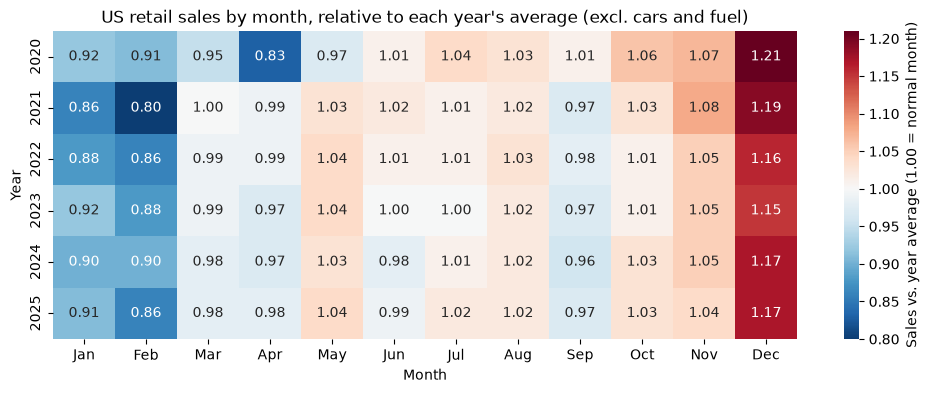

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))
sns.heatmap(
    table,
    annot=True,          # show the numbers in the cells
    fmt=".2f",           # 2 decimals
    cmap="RdBu_r",       # blue = below normal, red = above normal
    center=1,            # 1.00 (a normal month) is the neutral middle colour
    cbar_kws={"label": "Sales vs. year average (1.00 = normal month)"}
)
plt.title("US retail sales by month, relative to each year's average (excl. cars and fuel)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.show()

In [18]:
def prepare(file_name, category):
    df = pd.read_csv(file_name)
    df.columns = ["date", "sales"]                      # step 2: works for any FRED file
    df["date"] = pd.to_datetime(df["date"])             # step 3
    df = df[(df["date"] >= "2020-01-01") & (df["date"] <= "2025-12-31")]   # keep 2020–2025
    df["year"] = df["date"].dt.year                     # step 4
    df["month"] = df["date"].dt.month
    df["year_avg"] = df.groupby("year")["sales"].transform("mean")          # step 5
    df["seasonal_index"] = df["sales"] / df["year_avg"]
    df["category"] = category                           # label, so we can stack them
    return df

In [19]:
files = {
    "toys.csv": "Toys & hobby",
    "clothing.csv": "Clothing",
    "electronics.csv": "Electronics",
    "online.csv": "Online",
    "grocery.csv": "Grocery",
}

all_categories = pd.concat([prepare(file, name) for file, name in files.items()])

In [27]:
december = all_categories[all_categories["month"] == 12]
# ascending so the biggest December lift ends up at the top of the horizontal bar chart
dec_avg = (december.groupby("category")["seasonal_index"]
           .mean()
           .sort_values()
           .reset_index())
dec_avg


,category,seasonal_index
0,Grocery,1.067476
1,Online,1.299179
2,Electronics,1.350335
3,Clothing,1.617681
4,Toys & hobby,1.644605


In [21]:
all_categories

,date,sales,year,month,year_avg,seasonal_index,category
0,2020-01-01,1003,2020,1,1200.083333,0.835775,Toys & hobby
1,2020-02-01,1025,2020,2,1200.083333,0.854107,Toys & hobby
2,2020-03-01,734,2020,3,1200.083333,0.611624,Toys & hobby
3,2020-04-01,303,2020,4,1200.083333,0.252482,Toys & hobby
4,2020-05-01,941,2020,5,1200.083333,0.784112,Toys & hobby
...,...,...,...,...,...,...,...
67,2025-08-01,77982,2025,8,75939.250000,1.026900,Grocery
68,2025-09-01,74160,2025,9,75939.250000,0.976570,Grocery
69,2025-10-01,77532,2025,10,75939.250000,1.020974,Grocery
70,2025-11-01,77026,2025,11,75939.250000,1.014311,Grocery


In [26]:

dec_avg["pct_above_normal"] = ((dec_avg["seasonal_index"] - 1) * 100).round(0)
fig = px.bar(dec_avg, x="pct_above_normal", y="category", orientation="h",
             text="pct_above_normal",
             title="December sales: % above a normal month (2020–2025)",
             labels={"pct_above_normal": "% above yearly average", "category": ""})
fig.update_traces(texttemplate="+%{text}%")
fig.show()

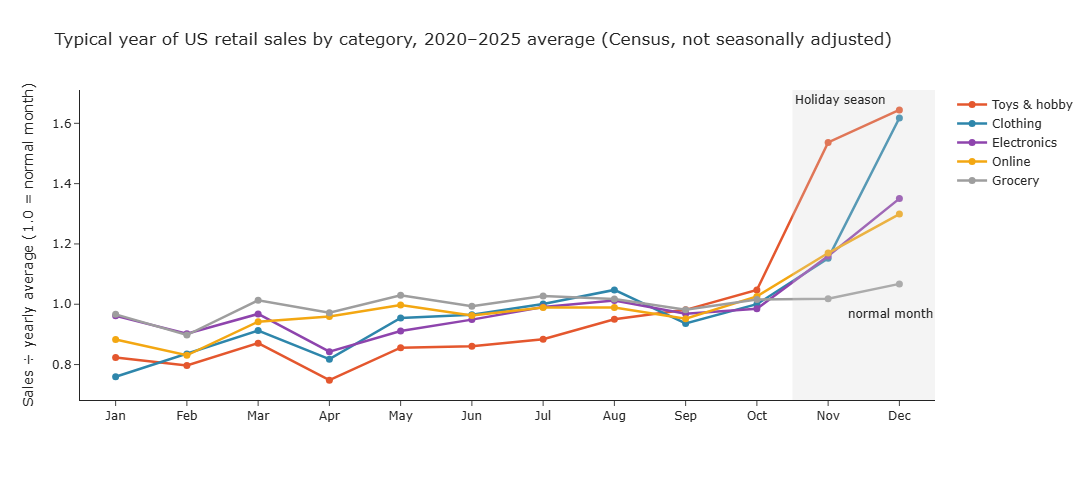

In [ ]:
import plotly.express as px

month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

# average "typical year" per category
profile = (all_categories
           .groupby(["category", "month"])["seasonal_index"]
           .mean()
           .reset_index())

# fixed colours: each category keeps the same colour in every chart; grocery = grey (comparison)
colors = {
    "Toys & hobby": "#E4572E",
    "Clothing":     "#2E86AB",
    "Electronics":  "#8E44AD",
    "Online":       "#F3A712",
    "Grocery":      "#9E9E9E",
}

fig = px.line(
    profile, x="month", y="seasonal_index", color="category",
    markers=True,
    color_discrete_map=colors,
    category_orders={"category": ["Toys & hobby", "Clothing", "Electronics", "Online", "Grocery"]},
    labels={"month": "", "seasonal_index": "Sales ÷ yearly average (1.0 = normal month)", "category": "Category"},
    title="Typical year of US retail sales by category, 2020–2025 average (Census, not seasonally adjusted)",
    template="simple_white",
)

# shade the holiday season (Nov–Dec)
fig.add_vrect(x0=10.5, x1=12.5, fillcolor="lightgrey", opacity=0.25, line_width=0,
              annotation_text="Holiday season", annotation_position="top left")

# reference line at 1.0 = a normal month
fig.add_hline(y=1, line_dash="dash", line_color="grey",
              annotation_text="normal month", annotation_position="bottom right")

fig.update_traces(line_width=2.5, marker_size=7,
                  hovertemplate="%{x}: %{y:.2f}× normal<extra>%{fullData.name}</extra>")
fig.update_xaxes(tickvals=list(range(1, 13)), ticktext=month_names, range=[0.5, 12.5])
fig.update_yaxes(tickformat=".1f")
fig.update_layout(legend_title_text="", height=480, margin=dict(t=90))

fig.show()